In [1]:
# %%
import qiskit
from matplotlib import pyplot as plt
import matplotlib as mpl
from qiskit.visualization import circuit_drawer


In [2]:

# def d_cyclic_stabilziers(d: int):
#     def rotate(l: list, n: int):
#         return l[n:] + l[:n]

#     t = (d-1)//2
#     stab_init = 'ZX'+ 'I'*t +'XZ'
#     return [rotate(stab_init,n) for n in range()]


class FiveQubitCode():
    stabilizers = ['XZZXI',
                   'IXZZX',
                   'XIXZZ',
                   'ZXIXZ']
    
    def encoder() -> qiskit.QuantumCircuit:
        """Construct encoder circuit for 5-qubit code. Qubit 0 is encoded qubit

        :return: _description_
        :rtype: qiskit.QuantumCircuit
        """
        q_reg = qiskit.QuantumRegister(5)
        qcirc = qiskit.QuantumCircuit(q_reg,name='Encoder')
        
        # Initializr data qubits to |+>
        qcirc.h(q_reg[:-1])
        
        # Add CNOTs
        for i in range(4):
            qcirc.cnot(q_reg[i],q_reg[-1])
        
        for i in range(5):
            qcirc.cz(q_reg[i],q_reg[(i+1)%5])
        
        return qcirc

    def decoder() -> qiskit.QuantumCircuit:
        """Construct 5-qubit code decoder, which is simply the encoder circuit reversed.

        :return: _description_
        :rtype: qiskit.QuantumCircuit
        """
        qcirc = FiveQubitCode.encoder()
        qcirc.name = 'Decoder'
        return qcirc.reverse_ops()

    def stab_meas() -> qiskit.QuantumCircuit:
        num_ancilla = len(FiveQubitCode.stabilizers)
        num_qubits = len(FiveQubitCode.stabilizers[0])
        
        a_reg = qiskit.AncillaRegister(num_ancilla,name='a')
        c_reg = qiskit.ClassicalRegister(num_ancilla,name='m')
        q_reg = qiskit.QuantumRegister(num_qubits,name='q')
        qcirc = qiskit.QuantumCircuit(q_reg,a_reg,c_reg,name='Measurement')
        
        # Prep ancilla in |+> state
        qcirc.h(a_reg)

        # Construct controlled unitary measurements
        for j,stab in enumerate(FiveQubitCode.stabilizers):
            qcirc.barrier()   
            for i,s in enumerate(stab):
                if s != 'I':
                    if s == 'Z':
                        qcirc.cz(a_reg[j],q_reg[i])
                    elif s == 'X':
                        qcirc.cnot(a_reg[j],q_reg[i])
            
            # X-basis measurement
            qcirc.h(a_reg[j])
            qcirc.measure(a_reg[j],c_reg[j])  
        return qcirc
    


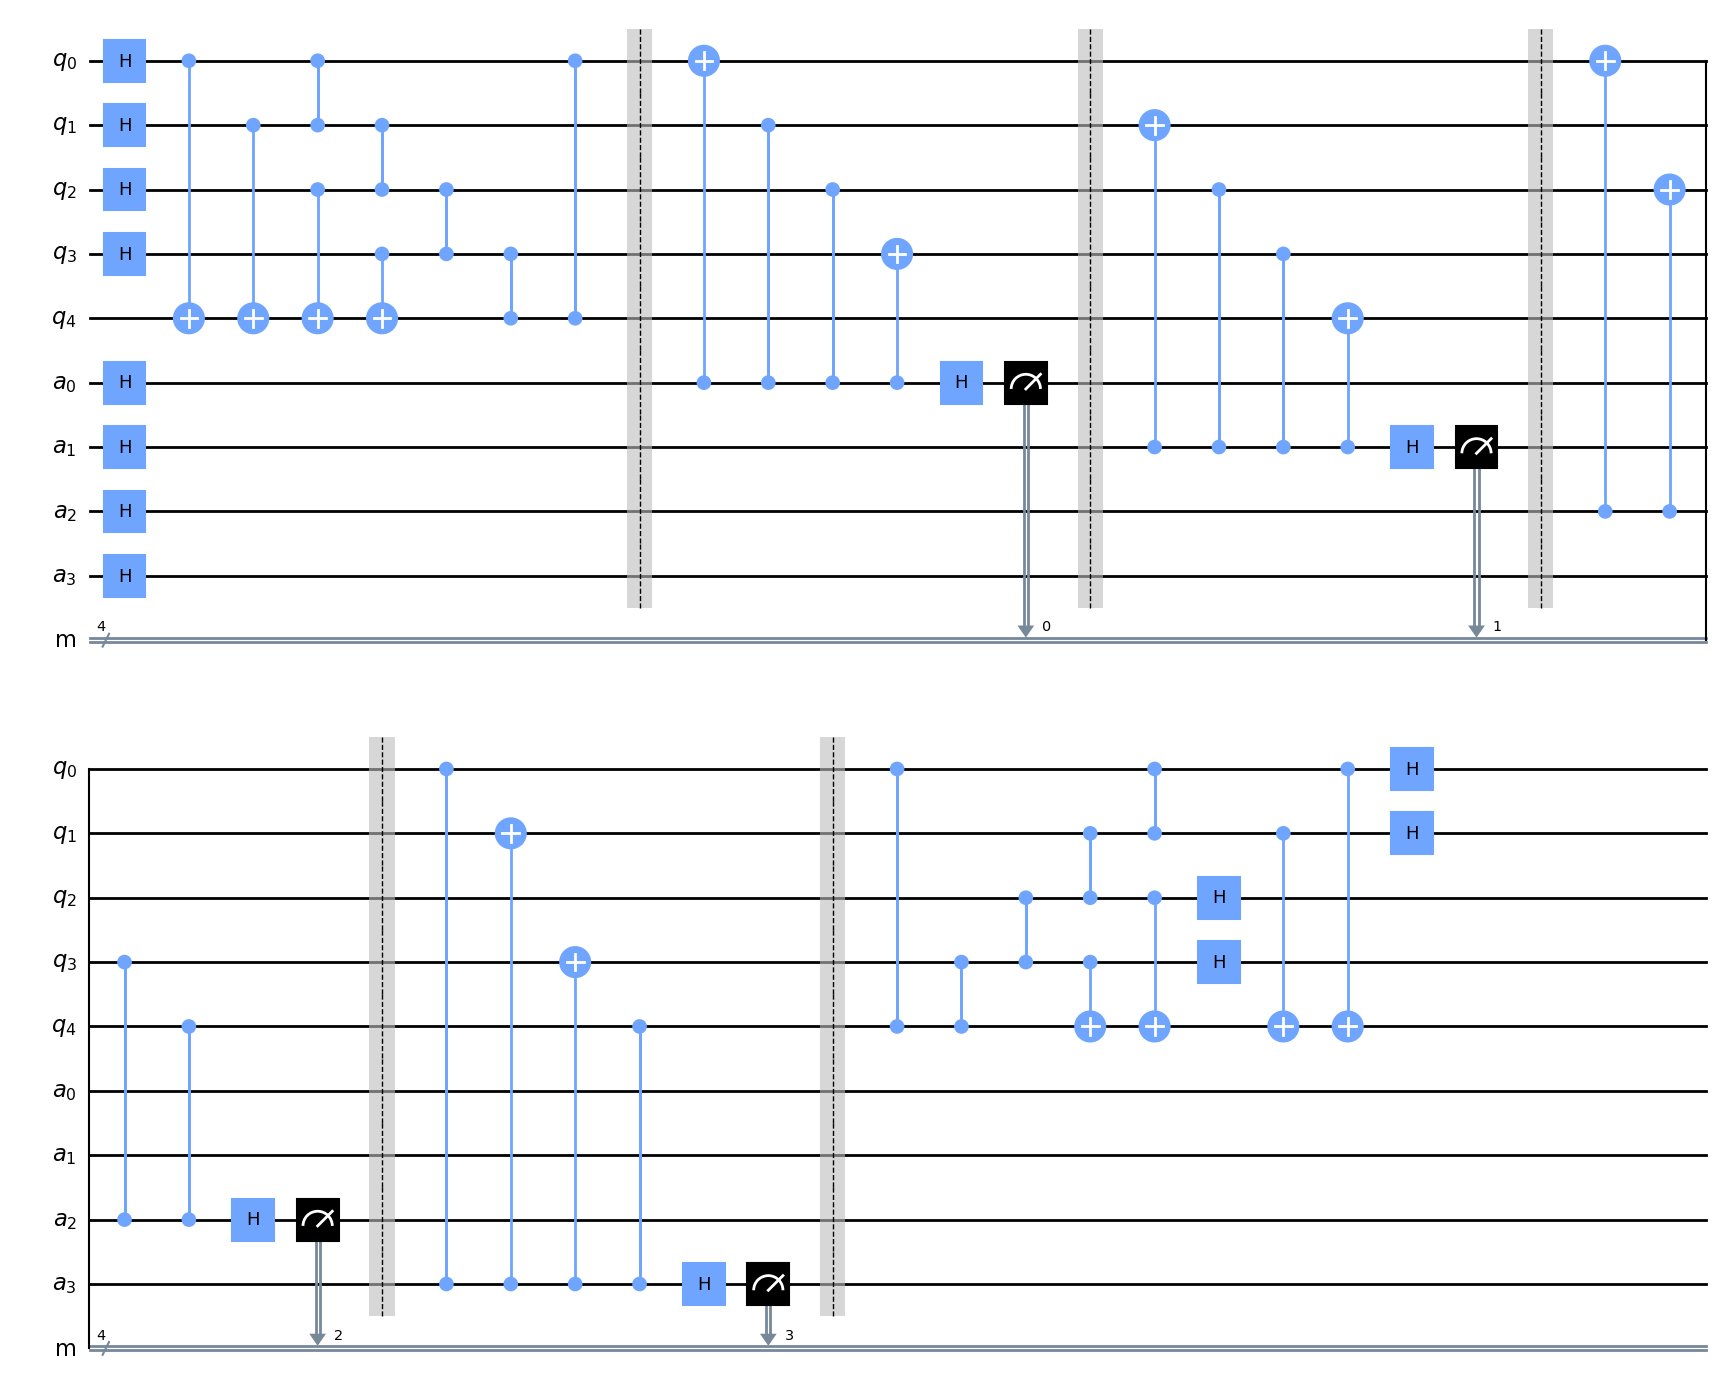

In [3]:
circ_meas = FiveQubitCode.stab_meas()
circ_enc = FiveQubitCode.encoder()
circ_dec = FiveQubitCode.decoder()

# circ_enc.barrier()
qcirc = circ_meas.compose(circ_enc,front=True)
qcirc.barrier()
qcirc = qcirc.compose(circ_dec)
qcirc.draw(output='mpl')
